In [1]:
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
import numpy as np
import tensorflow as tf
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout, RepeatVector, TimeDistributed

In [2]:
df = pd.read_csv('GOOGL.csv')

In [3]:
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2004-08-19,2.490664,2.591785,2.390042,2.499133,2.499133,897427216
1,2004-08-20,2.515820,2.716817,2.503118,2.697639,2.697639,458857488
2,2004-08-23,2.758411,2.826406,2.716070,2.724787,2.724787,366857939
3,2004-08-24,2.770615,2.779581,2.579581,2.611960,2.611960,306396159
4,2004-08-25,2.614201,2.689918,2.587302,2.640104,2.640104,184645512


In [4]:
# Extract "Date" and "Close" feature colums from the dataframe.
df = df[['Date', 'Close']]

In [5]:
# Concise summary of a DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4858 entries, 0 to 4857
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    4858 non-null   object 
 1   Close   4858 non-null   float64
dtypes: float64(1), object(1)
memory usage: 76.0+ KB


In [6]:
df['Date'].min(), df['Date'].max()

('2004-08-19', '2023-12-05')

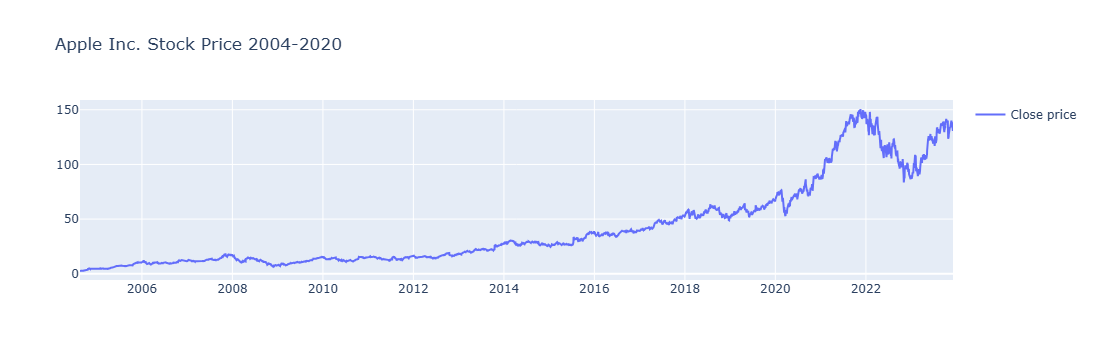

In [7]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=df['Date'], y=df['Close'], name='Close price'))
fig.update_layout(showlegend=True, title='Apple Inc. Stock Price 2004-2020')
fig.show()

In [8]:
train = df.loc[df['Date'] <= '2017-12-24']
test = df.loc[df['Date'] > '2017-12-24']
train.shape, test.shape

((3362, 2), (1496, 2))

In [9]:
scaler = StandardScaler()
scaler = scaler.fit(np.array(train['Close']).reshape(-1,1))

train['Close'] = scaler.transform(np.array(train['Close']).reshape(-1,1))
test['Close'] = scaler.transform(np.array(test['Close']).reshape(-1,1))

C:\Users\student\AppData\Local\Temp\ipykernel_7448\3901342107.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\student\AppData\Local\Temp\ipykernel_7448\3901342107.py:5: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



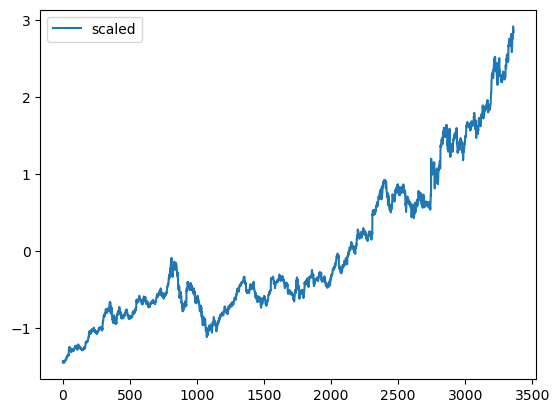

In [10]:
# Visualize scaled data
plt.plot(train['Close'], label = 'scaled')
plt.legend()
plt.show()

In [11]:
TIME_STEPS=30

def create_sequences(X, y, time_steps=TIME_STEPS):
    X_out, y_out = [], []
    for i in range(len(X)-time_steps):
        X_out.append(X.iloc[i:(i+time_steps)].values)
        y_out.append(y.iloc[i+time_steps])
    
    return np.array(X_out), np.array(y_out)

X_train, y_train = create_sequences(train[['Close']], train['Close'])
X_test, y_test = create_sequences(test[['Close']], test['Close'])
print("Training input shape: ", X_train.shape)
print("Testing input shape: ", X_test.shape)

Training input shape:  (3332, 30, 1)
Testing input shape:  (1466, 30, 1)


In [12]:
X_train[3331]

array([[2.7266968 ],
       [2.71313038],
       [2.70326373],
       [2.70432702],
       [2.68268055],
       [2.73197026],
       [2.67494012],
       [2.67192072],
       [2.74043324],
       [2.74668493],
       [2.76646034],
       [2.82429834],
       [2.79537934],
       [2.68586997],
       [2.68480669],
       [2.63700529],
       [2.5881406 ],
       [2.61565634],
       [2.67192072],
       [2.72529346],
       [2.75132056],
       [2.76854429],
       [2.76590739],
       [2.76646034],
       [2.80277928],
       [2.86674122],
       [2.92181482],
       [2.89434194],
       [2.86997351],
       [2.86435966]])

In [13]:
# set seed to regenerate same sequence of random numbers.
np.random.seed(21)
tf.random.set_seed(21)

In [14]:
model = Sequential()
model.add(LSTM(128, activation = 'tanh', input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(rate=0.2))
model.add(RepeatVector(X_train.shape[1]))
model.add(LSTM(128, activation = 'tanh', return_sequences=True))
model.add(Dropout(rate=0.2))
model.add(TimeDistributed(Dense(X_train.shape[2])))
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
model.summary()

C:\Users\student\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 30, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 1)          │           129 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 198,273 (774.50 KB)

 Trainable params: 198,273 (774.50 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(X_train,
                    y_train,
                    epochs=100,
                    batch_size=32,
                    validation_split=0.1,
                    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, mode='min')],
                    shuffle=False)

Epoch 1/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.0615 - val_loss: 0.2380
Epoch 2/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0239 - val_loss: 0.0728
Epoch 3/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0183 - val_loss: 0.0565
Epoch 4/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0172 - val_loss: 0.0437
Epoch 5/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0157 - val_loss: 0.0341
Epoch 6/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0175 - val_loss: 0.0406
Epoch 7/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0147 - val_loss: 0.0353
Epoch 8/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0137 - val_loss: 0.0319
Epoch 9/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0151 - val_loss: 0.0214
Epoch 10/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0153 - val_loss: 0.0193
Epoch 11/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0157 - val_loss: 0.1362
Epoch 12/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step

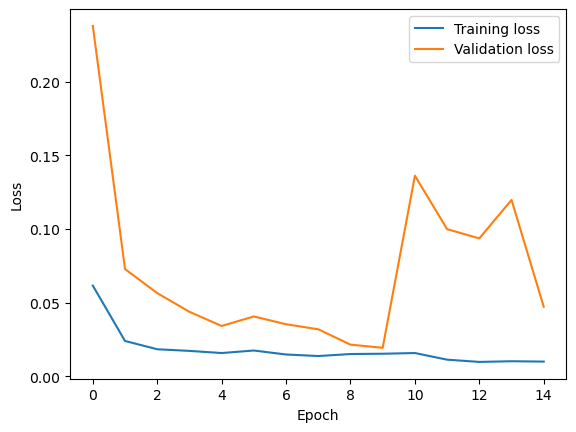

In [16]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend();

105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Reconstruction error threshold: 0.4244252403914374


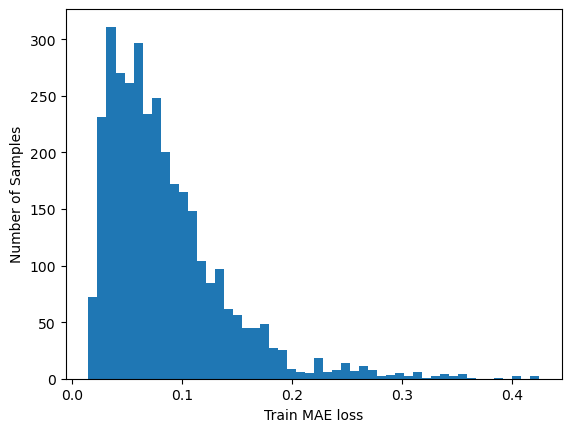

In [17]:
# Mean Absolute Error loss
X_train_pred = model.predict(X_train)
train_mae_loss = np.mean(np.abs(X_train_pred - X_train), axis=1)

plt.hist(train_mae_loss, bins=50)
plt.xlabel('Train MAE loss')
plt.ylabel('Number of Samples');

# Set reconstruction error threshold
threshold = np.max(train_mae_loss)

print('Reconstruction error threshold:',threshold)

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


Text(0, 0.5, 'Number of samples')

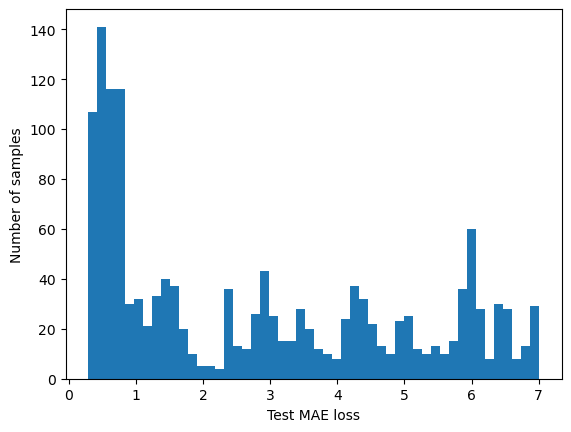

In [18]:
X_test_pred = model.predict(X_test, verbose=1)
test_mae_loss = np.mean(np.abs(X_test_pred-X_test), axis=1)

plt.hist(test_mae_loss, bins=50)
plt.xlabel('Test MAE loss')
plt.ylabel('Number of samples')

In [19]:
anomaly_df = pd.DataFrame(test[TIME_STEPS:])
anomaly_df['loss'] = test_mae_loss
anomaly_df['threshold'] = threshold
anomaly_df['anomaly'] = anomaly_df['loss'] > anomaly_df['threshold']

In [20]:
anomaly_df.head()

,Date,Close,loss,threshold,anomaly
3392,2018-02-08,2.600219,0.552602,0.424425,True
3393,2018-02-09,2.754425,0.604673,0.424425,True
3394,2018-02-12,2.814645,0.627406,0.424425,True
3395,2018-02-13,2.815325,0.636581,0.424425,True
3396,2018-02-14,2.890174,0.642729,0.424425,True


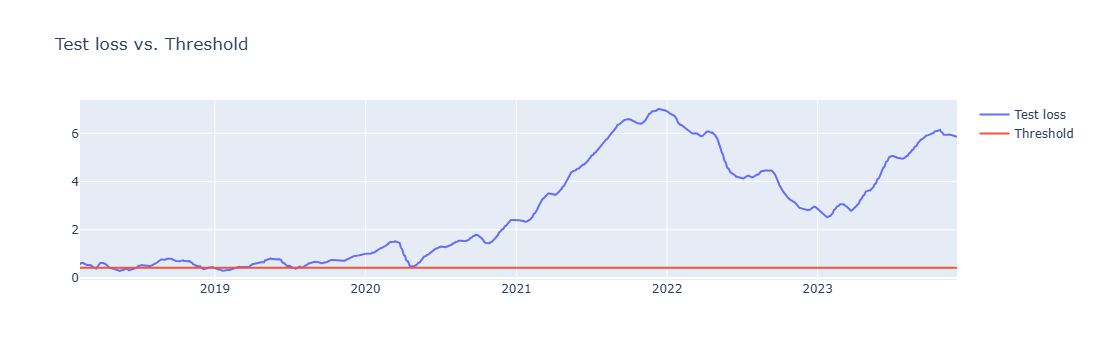

In [21]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=anomaly_df['Date'], y=anomaly_df['loss'], name='Test loss'))
fig.add_trace(go.Scatter(x=anomaly_df['Date'], y=anomaly_df['threshold'], name='Threshold'))
fig.update_layout(showlegend=True, title='Test loss vs. Threshold')
fig.show()

In [22]:
anomalies = anomaly_df.loc[anomaly_df['anomaly'] == True]
anomalies.head()

,Date,Close,loss,threshold,anomaly
3392,2018-02-08,2.600219,0.552602,0.424425,True
3393,2018-02-09,2.754425,0.604673,0.424425,True
3394,2018-02-12,2.814645,0.627406,0.424425,True
3395,2018-02-13,2.815325,0.636581,0.424425,True
3396,2018-02-14,2.890174,0.642729,0.424425,True


In [23]:
anomalies.shape

(1360, 5)

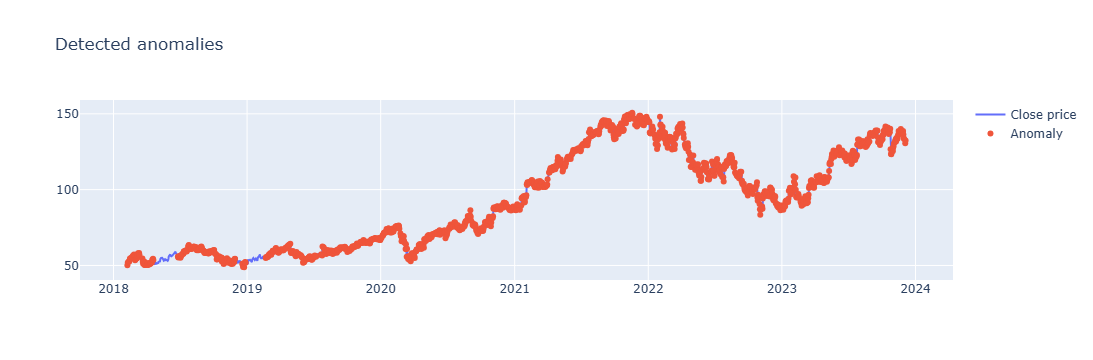

In [24]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=anomaly_df['Date'], y=scaler.inverse_transform(anomaly_df[['Close']].values).flatten(), name='Close price'))
fig.add_trace(go.Scatter(x=anomalies['Date'], y=scaler.inverse_transform(anomalies[['Close']].values).flatten(), mode='markers', name='Anomaly'))
fig.update_layout(showlegend=True, title='Detected anomalies')
fig.show()